# BrushCue Example: Sunset Filter

<a href="https://colab.research.google.com/github/ditotechnologies/brushcue/blob/main/examples/sunset_filter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

You can use this tool online at https://www.brushcue.com/tools/sunset-filter

In [ ]:
!pip install brushcue

[wgpu] using backend Vulkan — adapter 'NVIDIA GeForce RTX 5070' (DiscreteGpu), driver 'NVIDIA'


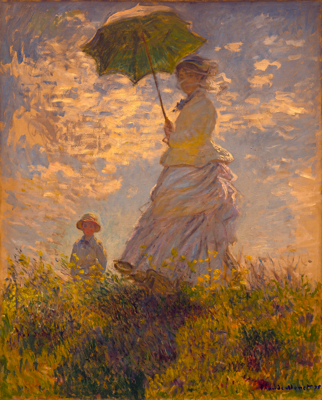

In [1]:
import io
from PIL import Image

import brushcue as bc

intensity = 0.6
input_image = bc.Composition.monet_women_with_parasol()
graph = (
    input_image.target_white_kelvin((5003.0 - (1500.0 * intensity)))
    .color_transformer_shader(
        "  let highlight_weight = smoothstep(0.25, 0.65, input.r);\n  let tint = mix(shadow_tint, highlight_tint, highlight_weight) * amount;\n  return vec4<f32>(input.r, input.g + tint.x, input.b + tint.y, input.a);",
        "",
        bc.ColorRepresentation.oklab_a(),
        bc.ColorRepresentation.oklab_a(),
        bc.Dictionary.create()
        .add("amount", intensity)
        .add("shadow_tint", bc.Vector2f.from_components(0.05, (-0.04)))
        .add("highlight_tint", bc.Vector2f.from_components(0.05, 0.07)),
    )
    .saturation_adjust((1.0 + (0.25 * intensity)))
    .brightness_adjust(((-0.05) * intensity))
    .vignette(
        bc.Vector2f.from_components(
            (input_image.bounds().width() / 2.0), (input_image.bounds().height() / 2.0)
        ),
        (input_image.bounds().width() / 2.0),
        (input_image.bounds().height() / 2.0),
        (input_image.bounds().width() * 0.35),
        (0.4 * intensity),
    )
    .crop(input_image.bounds())
)

ctx = bc.Context()
composition = graph.execute(ctx)
data_bytes = composition.to_image_bytes(ctx)
img = Image.open(io.BytesIO(data_bytes))
img.thumbnail((400, 400))  # Remove this line for full resolution
img
